# 01 — IBKR intraday

Loads 5-minute bars pulled by `_pull_ibkr_bars.py` from the live IB Gateway (read-only).

**Prerequisites:**
1. IB Gateway running on `127.0.0.1:4002` (paper, logged in to DUP662235).
2. Run `python _pull_ibkr_bars.py` in this directory before opening this notebook.

**Symbols:** MES, MGC, MNQ futures (June 2026 = M6) + SPY, QQQ stocks. 30 calendar days, 5-minute bars, extended hours included.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA = Path.cwd() / "data"
ibkr_files = sorted(DATA.glob("*_5m.parquet"))
assert ibkr_files, f"No 5-minute bars found in {DATA}. Run `python _pull_ibkr_bars.py` first."

bars = {p.stem.replace('_5m', ''): pd.read_parquet(p) for p in ibkr_files}
for name, df in bars.items():
    print(f"{name:4s}  {len(df):5d} bars  {df.index.min()} -> {df.index.max()}")

MES    8005 bars  2026-03-26 17:00:00-05:00 -> 2026-05-07 00:45:00-05:00
MGC    8098 bars  2026-03-25 18:00:00-04:00 -> 2026-05-07 01:45:00-04:00
MNQ    8005 bars  2026-03-26 17:00:00-05:00 -> 2026-05-07 00:45:00-05:00
QQQ    5760 bars  2026-03-25 04:00:00-04:00 -> 2026-05-06 19:55:00-04:00
SPY    5760 bars  2026-03-25 04:00:00-04:00 -> 2026-05-06 19:55:00-04:00


## MES recent intraday — last 2 days

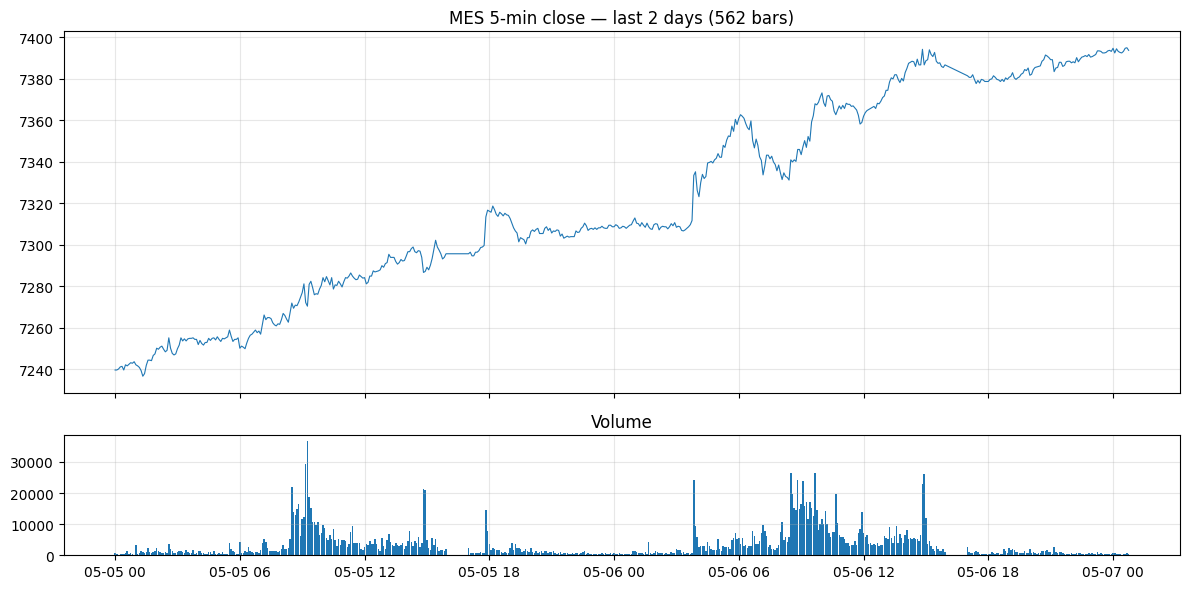

In [2]:
mes = bars['MES']
recent = mes.loc[mes.index >= mes.index.max().normalize() - pd.Timedelta(days=2)]
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True, gridspec_kw={'height_ratios': [3, 1]})
ax1.plot(recent.index, recent['close'], linewidth=0.8)
ax1.set_title(f'MES 5-min close — last 2 days ({len(recent)} bars)')
ax1.grid(alpha=0.3)
ax2.bar(recent.index, recent['volume'], width=0.003)
ax2.set_title('Volume')
ax2.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Intraday volume profile by hour-of-day

Useful sanity check: futures have characteristic volume bumps at session opens (RTH 9:30 ET, Asia open, London open). If this looks flat or wrong-shaped, the data fetch is suspect.

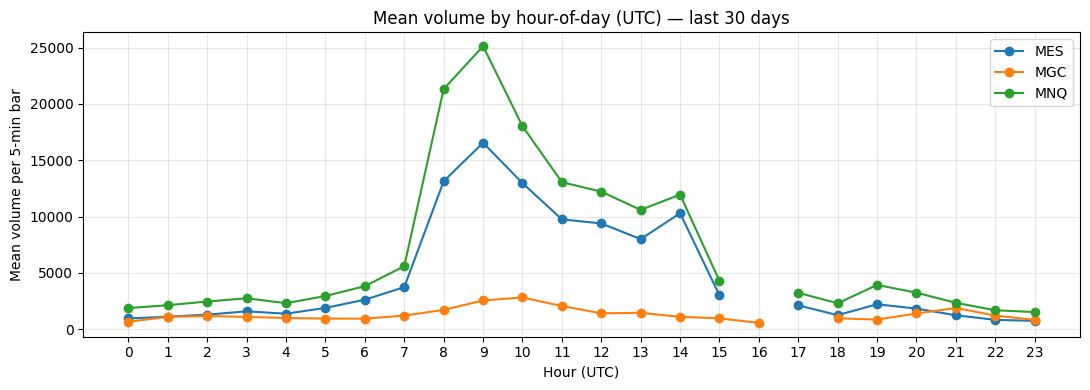

In [3]:
def hourly_volume_profile(df, label):
    return df.groupby(df.index.hour)['volume'].mean().rename(label)

profiles = pd.DataFrame({
    name: hourly_volume_profile(df, name)
    for name, df in bars.items()
    if name in ('MES', 'MNQ', 'MGC')
})

fig, ax = plt.subplots(figsize=(11, 4))
profiles.plot(ax=ax, marker='o')
ax.set_title('Mean volume by hour-of-day (UTC) — last 30 days')
ax.set_xlabel('Hour (UTC)')
ax.set_ylabel('Mean volume per 5-min bar')
ax.grid(alpha=0.3)
ax.set_xticks(range(0, 24))
plt.tight_layout()
plt.show()

## Intraday return autocorrelation

Lag-1 autocorrelation of 5-min returns — closer to 0 means efficient/random; positive = momentum at this timeframe; negative = mean-reversion. MES near 0 typical; MGC sometimes shows mild positive at intraday.

In [4]:
for name, df in bars.items():
    rets = df['close'].pct_change().dropna()
    ac = rets.autocorr(lag=1)
    print(f"{name:4s}  n={len(rets):5d}  mean_ret={rets.mean():+.6f}  std={rets.std():.5f}  lag1_autocorr={ac:+.4f}")

MES   n= 8004  mean_ret=+0.000015  std=0.00055  lag1_autocorr=-0.0037
MGC   n= 8097  mean_ret=+0.000005  std=0.00101  lag1_autocorr=+0.0024
MNQ   n= 8004  mean_ret=+0.000023  std=0.00069  lag1_autocorr=+0.0086
QQQ   n= 5759  mean_ret=+0.000029  std=0.00081  lag1_autocorr=+0.0149
SPY   n= 5759  mean_ret=+0.000019  std=0.00064  lag1_autocorr=+0.0098


## Where to go from here

- Pull longer history: edit `_pull_ibkr_bars.py` → `DURATION = "6 M"` (or `"1 Y"`).
- Pull finer bars: change `BAR_SIZE` to `"1 min"` (warning: 30 D × 1 min ≈ 12K bars per symbol — IBKR pacing limits may apply).
- Different symbols: add to the `CONTRACTS` dict — any qualified IBKR contract works.
- Move from notebook scratch into `~/Code/jarvis-quant/src/signals/` once you have a pattern worth keeping.